# Affine transform - with label(bbox & keypoints)

전체 이미지를 affine transform 하고, 그 다음에 변형된 bbox, keypoint 좌표까지 구해내는 셋팅

transform matrix는 wikipedia에 있는 수식 참고
https://en.wikipedia.org/wiki/Affine_transformation#Image_transformation

변환 순서
1. xflip (좌우 플립)
2. resizing
3. rotating

rotating 하고 나서 원본 사이즈 넘어가는 부분 처리
- bbox: 원본 사이즈에 맞춰서 축소하는 방향으로 조정
- keypoints: 해당 키포인트를 버린다.

In [23]:
import torch

from torchvision.transforms.v2.functional import affine
from torchvision.transforms.v2 import InterpolationMode

from torchvision.utils import draw_bounding_boxes

In [8]:
image_path = '/home/dev/pose/data/coco/images/train2017/000000537548.jpg'
bbox = [267, 104, 229, 320]
kp = torch.tensor([[  0,   0,   0],
                   [  0,   0,   0],
                   [  0,   0,   0],
                   [  0,   0,   0],
                   [  0,   0,   0],
                   [325, 160,   2],
                   [398, 177,   2],
                   [  0,   0,   0],
                   [437, 238,   2],
                   [  0,   0,   0],
                   [477, 270,   2],
                   [287, 255,   1],
                   [339, 267,   2],
                   [  0,   0,   0],
                   [423, 314,   2],
                   [  0,   0,   0],
                   [355, 367,   2]], dtype=torch.int32)

In [2]:
%matplotlib inline
from matplotlib import pyplot as plt
from torchvision.io import read_image
from torchvision.transforms.v2 import ToPILImage

to_pil = ToPILImage()

COLOR_MAGENTA = (255, 0, 255) # RGB
COLOR_CYAN = (0, 255, 255) # RGB
COLOR_YELLOW = (255, 255, 0) # RGB

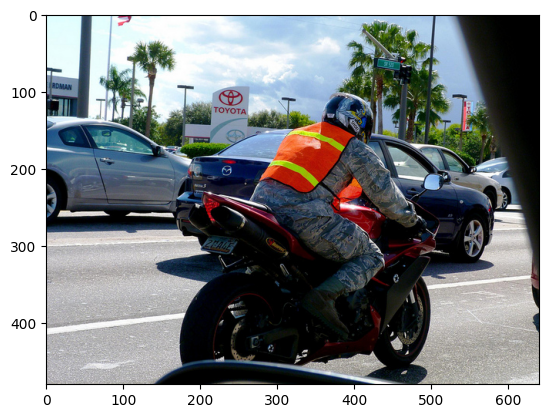

In [3]:
img = read_image(image_path)
plt_img = to_pil(img)

plt.imshow(plt_img)
plt.show()

# Bbox

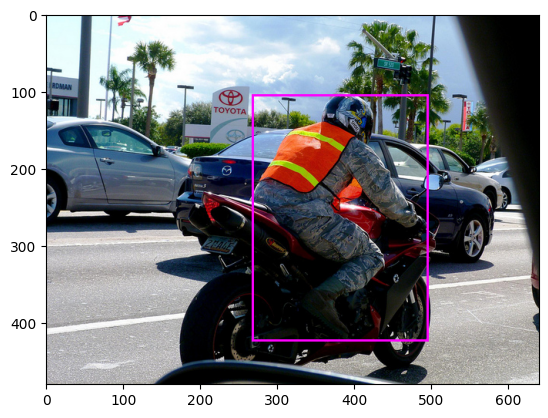

In [21]:
bbox_4p = torch.tensor([[bbox[0], bbox[1], bbox[0]+bbox[2], bbox[1]+bbox[3]]])

img = read_image(image_path)
img = draw_bounding_boxes(img, bbox_4p, colors=COLOR_MAGENTA, width=3)

img = to_pil(img)
plt.imshow(img)
plt.show()

### bbox - 회전

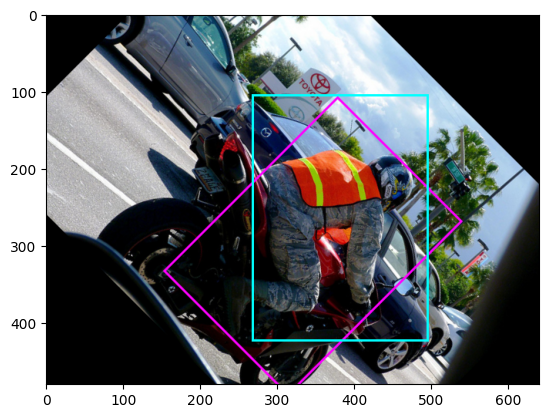

In [29]:
angle = 45          # angle in degree: -180 to 180
translate = [0, 0]  # horizontal and vertical translations
scale = 1.0         # overall scale
shear = [0, 0]
interpolation = InterpolationMode.BILINEAR
fill = None
center = None

img = read_image(image_path)
img = draw_bounding_boxes(img, bbox_4p, colors=COLOR_MAGENTA, width=3)   # original bbox (magenta)

img = affine(img, angle, translate, scale, shear, interpolation, fill, center)

tr_bbox_4p = bbox_4p
img = draw_bounding_boxes(img, tr_bbox_4p, colors=COLOR_CYAN, width=3)   # transformed bbox (cyan)

img = to_pil(img)
plt.imshow(img)
plt.show()

### bbox는 생각보다 난해하네 🤔🤔🤔

rotation하면 bbox를 다시 잡아야겠는데?

- 음.. 두 개 bbox 교점을 고려해서, 그 안을 bbox로 잡고, 그 안에 있는 keypoint로만 잘라버릴까?
- 아니면, crop을 하고 나서 rotating하고, 사진이 있는 영역과 padding을 넣게 되는 영역(=검정색 영역을 의미) 비중을 고려해서 가로로 컷팅한다든가 해야겠는걸

-> 이 아이디어가 일반화 가능하긴 할까? 위 사진은 인물이 가운데 있어서 그나마 되는거고, 안되는 케이스가 많을 것 같은데.

-> 그러면, 센터를 잘 잡아서 rotation 해야한다는 결론이 나온다. ✅ (그러면 그나마 bbox 잡는게 수월해질 것 같다.)

# Keypoints